In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, precision_recall_curve,
                              f1_score)
from sklearn.utils import class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import random
SEED = 42
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU Available:", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow version: 2.21.0
GPU Available: True


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Data of Dl/adult/adult.csv")
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [ ]:
missing_value = df.isnull().sum()
missing_value

,0
age,0
workclass,0
fnlwgt,0
education,0
education.num,0
marital.status,0
occupation,0
relationship,0
race,0
sex,0


#Chek missing values
we have missing values in data in the form of "str" (?) so we wil find it

In [ ]:
missing_counts = df.apply(lambda col: (col.astype(str).str.strip() == '?').sum())
print(missing_counts[missing_counts > 0])

workclass         1836
occupation        1843
native.country     583
dtype: int64


#Target Class Distribution

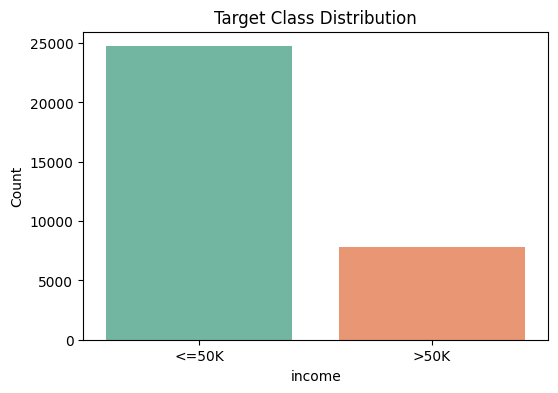

income
<=50K    75.919044
>50K     24.080956
Name: proportion, dtype: float64


In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="income", palette='Set2', hue= 'income')
plt.title('Target Class Distribution')
plt.xlabel('income')
plt.ylabel('Count')
plt.show()
Traget_rate = df['income'].value_counts(normalize=True) * 100
print(Traget_rate)

#Visulaizing Numuric feature distribution against income

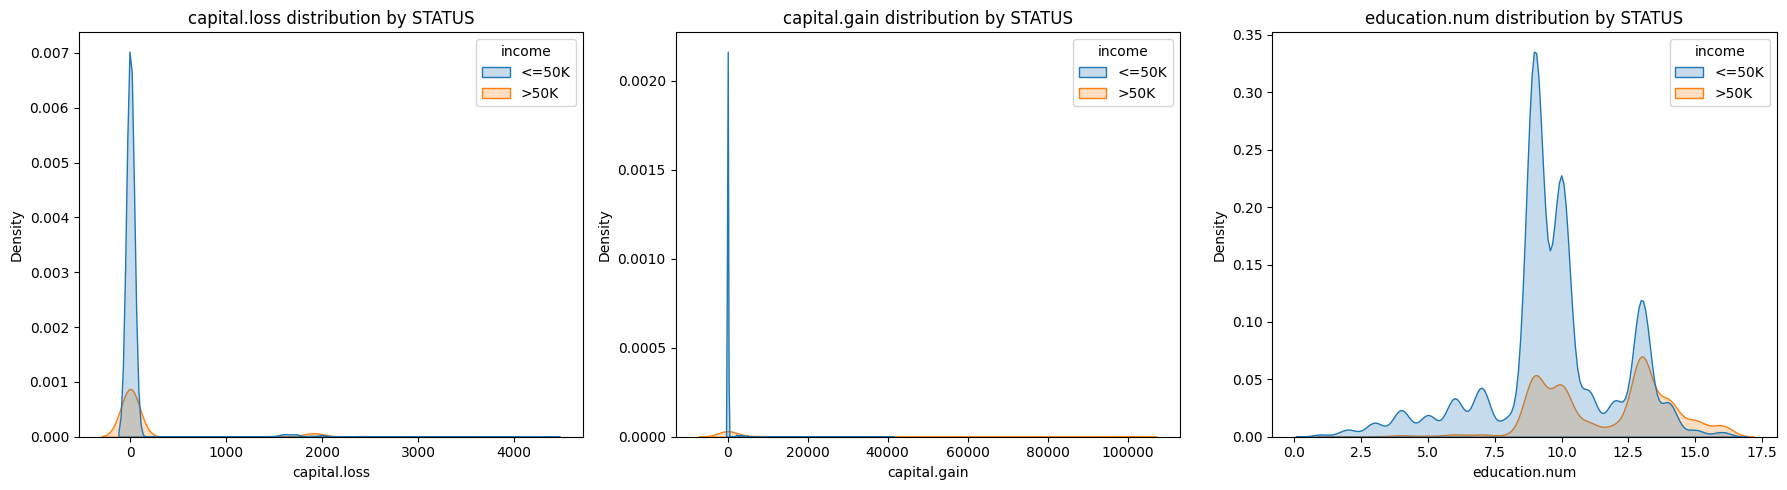

In [ ]:
numeric_cols = ['capital.loss', 'capital.gain', 'education.num']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(numeric_cols):
    sns.kdeplot(data = df, x=col, hue='income', fill=True, ax = axes[i])
    axes[i].set_title(f'{col} distribution by STATUS')
plt.tight_layout()
plt.show()


#Corelation Heatmap

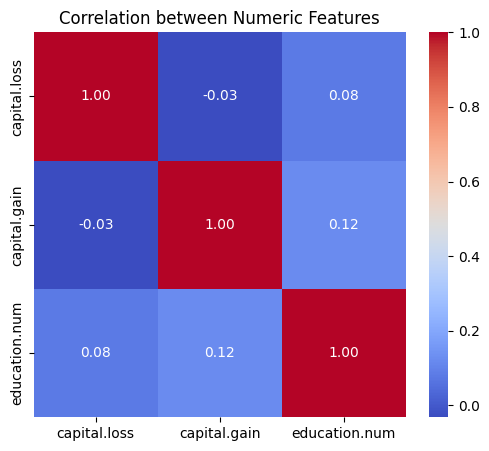

In [ ]:
plt.figure(figsize=(6, 5))
corr = df[numeric_cols].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation between Numeric Features')
plt.show()


# Clean data

#drop columns

In [ ]:
df = df.drop(columns=['fnlwgt','education'])



In [ ]:
# (?) ko nan may chag karay
cols_missing = ['workclass', 'occupation', 'native.country']
for col in cols_missing:
    df[col] = df[col].astype(str).str.strip().replace('?', np.nan)

#Fill it

In [ ]:
df['occupation'] = df['occupation'].fillna("Unknown")
df['workclass'] = df['workclass'].fillna("Unknown")
df['native.country'] = df['native.country'].fillna("Unknwn")
print(df[['occupation', 'workclass', 'native.country']].isnull().sum())

occupation        0
workclass         0
native.country    0
dtype: int64


# Prepare target column

In [ ]:
df['income'] = df['income'].astype(str).str.strip().map({'<=50K': 0, '>50K': 1})
print(df['income'].value_counts(dropna=False))

income
0    24720
1     7841
Name: count, dtype: int64


#Featur preparation

In [ ]:
X = df.drop(columns=['income'])
y = df['income']

numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['age', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Categorical features: ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']


#Train , validation and test split

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify = y)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp)

print("Train size:", X_train.shape[0])
print("Validation size:", X_val.shape[0])
print("Test size:", X_test.shape[0])


Train size: 22792
Validation size: 4884
Test size: 4885


# Preprocessing pipline

In [ ]:
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),                       # scaling numeric columns (numeric ko scale karna)
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)  # encoding categorical columns (category ko number mein badalna)
])

# Fitting only on training data, then transforming all three sets
X_train_processed = preprocessor.fit_transform(X_train)     # fit and transform on train only (sirf train par fit karna)
X_val_processed = preprocessor.transform(X_val)               # transform validation using train statistics
X_test_processed = preprocessor.transform(X_test)             # transform test using train statistics

print("Processed training shape:", X_train_processed.shape)


Processed training shape: (22792, 90)


#SMOTE (Handel Class Imbalance)
***Synthetic Minority Over-sampling Technique***.

In [ ]:
from imblearn.over_sampling import SMOTE

# Applying SMOTE only on training data (sirf training data ko balance karna)
smote = SMOTE(random_state = SEED)
X_train_smote, y_train_smote = smote.fit_resample(X_train_processed, y_train)

print("Before SMOTE:", np.bincount(y_train))
print("After SMOTE:", np.bincount(y_train_smote))

Before SMOTE: [17303  5489]
After SMOTE: [17303 17303]


#Building neural network

In [ ]:
input_dim = X_train_processed.shape[1]                # number of input features after preprocessing

def build_model(input_dim):
    model = keras.Sequential([                          # sequential stack of layers
        layers.Input(shape = (input_dim,)),

                                                        # normalizing activations for stable training
        layers.Dense(64, activation = 'relu'),              # first hidden layer, 64 neurons
        layers.BatchNormalization(),                       # normalizing activations for stable training
        layers.Dropout(0.3),                                # dropping 30 percent neurons to reduce overfitting

        layers.Dense(32, activation='relu'),               # second hidden layer, 32 neurons
        layers.BatchNormalization(),
        layers.Dropout(0.3),

        layers.Dense(16, activation='relu'),               # third hidden layer, 16 neurons
        layers.Dropout(0.2),

        layers.Dense(1, activation='sigmoid')               # output layer, single neuron for binary classification
    ])
    return model

model = build_model(input_dim)
model.summary()                                            # printing architecture summary (model ka structure dekhna)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,833 (34.50 KB)

 Trainable params: 8,641 (33.75 KB)

 Non-trainable params: 192 (768.00 B)

#Compiling the model

In [ ]:
# Compiling the model with loss, optimizer and metrics
model.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.001),     # Adam optimizer with a sensible default learning rate
    loss='binary_crossentropy',                                 # correct loss for binary classification
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),           # overall accuracy
        keras.metrics.Precision(name='precision'),                # precision on positive class
        keras.metrics.Recall(name='recall'),                       # recall on positive class
        keras.metrics.AUC(name='auc')                               # area under ROC curve
    ]
)
print ("Model Compiled")

Model Compiled


#Callback and training

In [ ]:
# Setting up training callbacks
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, restore_best_weights=True),   # stop early if no improvement (improvement na ho to rukna)
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=4, min_lr=1e-6),       # reduce learning rate on plateau
    keras.callbacks.ModelCheckpoint(
        'best_model.keras', monitor='val_loss', save_best_only=True)    # save only the best model version
]

# Training the model
history = model.fit(
    X_train_smote, y_train_smote,
    validation_data=(X_val_processed, y_val),
    epochs=100,                                    # upper limit, early stopping will likely stop sooner
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/100
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 80s 56ms/step - accuracy: 0.7920 - auc: 0.8705 - loss: 0.4484 - precision: 0.7668 - recall: 0.8393 - val_accuracy: 0.7977 - val_auc: 0.9045 - val_loss: 0.3824 - val_precision: 0.5506 - val_recall: 0.8690 - learning_rate: 0.0010
Epoch 2/100
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8218 - auc: 0.9003 - loss: 0.3938 - precision: 0.7931 - recall: 0.8708 - val_accuracy: 0.8065 - val_auc: 0.9065 - val_loss: 0.3718 - val_precision: 0.5641 - val_recall: 0.8639 - learning_rate: 0.0010
Epoch 3/100
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8287 - auc: 0.9051 - loss: 0.3853 - precision: 0.7997 - recall: 0.8771 - val_accuracy: 0.8108 - val_auc: 0.9076 - val_loss: 0.3643 - val_precision: 0.5713 - val_recall: 0.8580 - learning_rate: 0.0010
Epoch 4/100
1082/1082 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8302 - auc: 0.9090 - loss: 0.3766 - precision: 0.7988 - recall: 0.8828 - val_accuracy: 0.8098 - val_auc: 0.9070 - val_loss

# Visulizing Training History

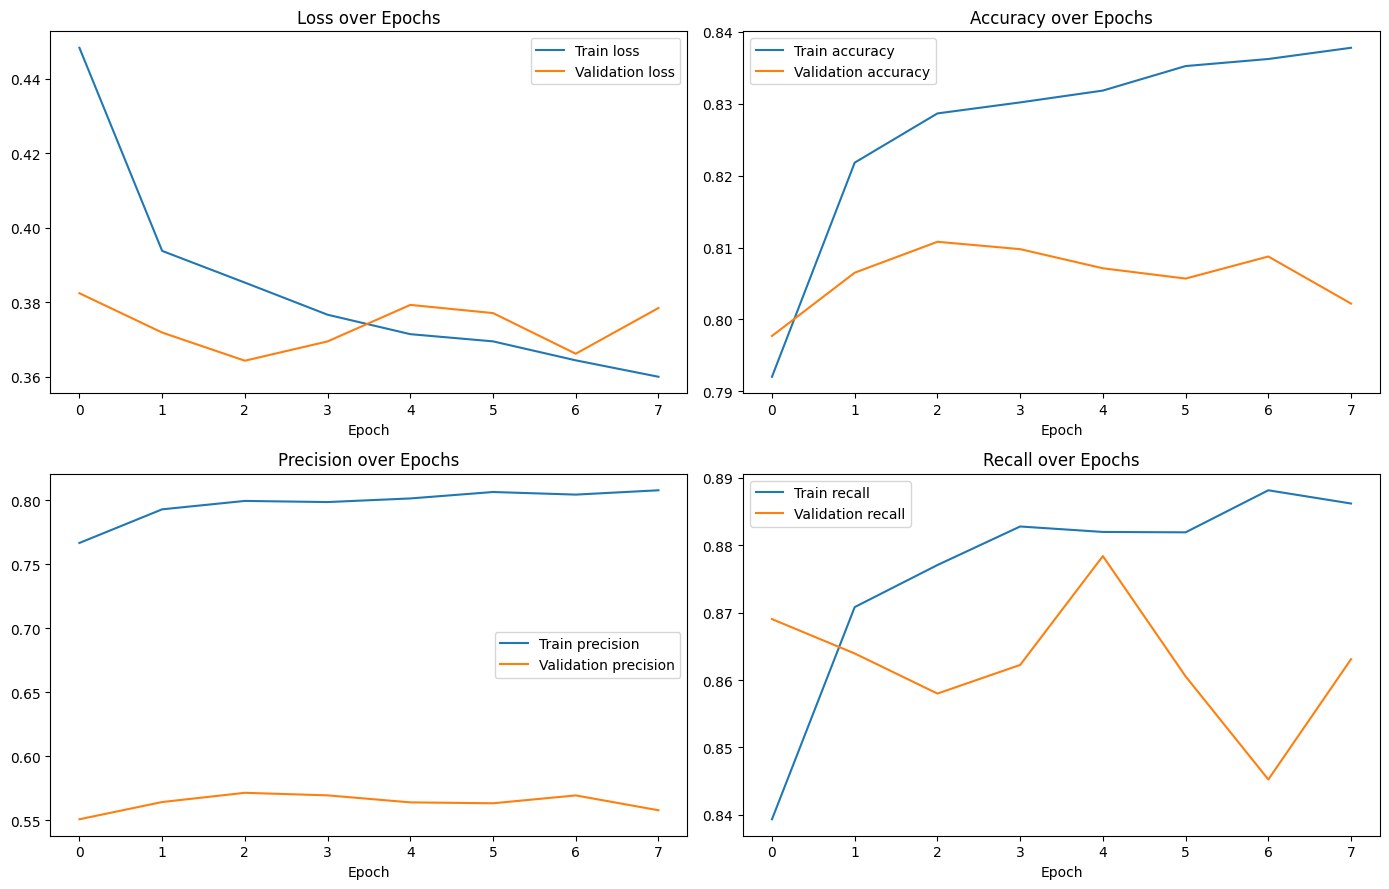

In [ ]:
# Plotting loss and key metrics across epochs
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

metrics_to_plot = ['loss', 'accuracy', 'precision', 'recall']
for ax, metric in zip(axes.flatten(), metrics_to_plot):
    ax.plot(history.history[metric], label=f'Train {metric}')            # training curve
    ax.plot(history.history[f'val_{metric}'], label=f'Validation {metric}')  # validation curve
    ax.set_title(f'{metric.capitalize()} over Epochs')
    ax.set_xlabel('Epoch')
    ax.legend()

plt.tight_layout()
plt.show()


#Model Evulaiton on test set

In [ ]:
# Generating predictions on the test set
y_pred_prob = model.predict(X_test_processed).flatten()   # predicted probabilities (probability values)
y_pred = (y_pred_prob >= 0.62).astype(int)                    # converting probability into class label using 0.5 threshold

# Printing full classification report
print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K']))

# ROC AUC score
auc_score = roc_auc_score(y_test, y_pred_prob)
print(f"Test ROC AUC Score: {auc_score:.4f}")


153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step
              precision    recall  f1-score   support

       <=50K       0.91      0.88      0.90      3709
        >50K       0.67      0.74      0.70      1176

    accuracy                           0.85      4885
   macro avg       0.79      0.81      0.80      4885
weighted avg       0.85      0.85      0.85      4885

Test ROC AUC Score: 0.9077


#Confusion matrix

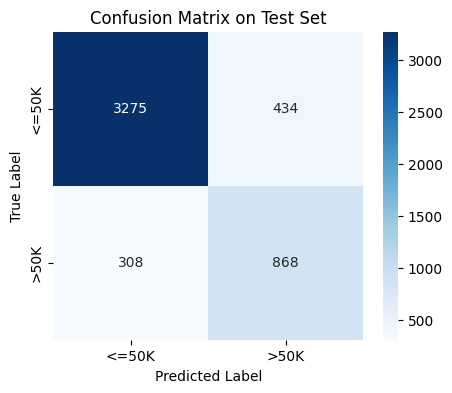

In [ ]:
# Plotting confusion matrix
cm = confusion_matrix(y_test, y_pred)                       # computing confusion matrix
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
plt.title('Confusion Matrix on Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()


# Plotting ROC curve


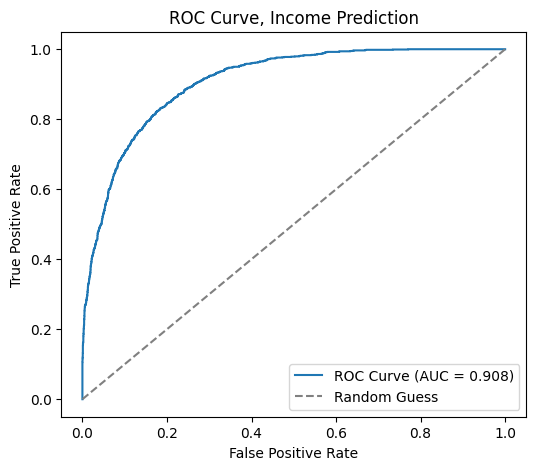

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_pred_prob)                # false positive and true positive rates
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve, Income Prediction')
plt.legend()
plt.show()


# Plotting Precision Recall curve, useful for imbalanced problems




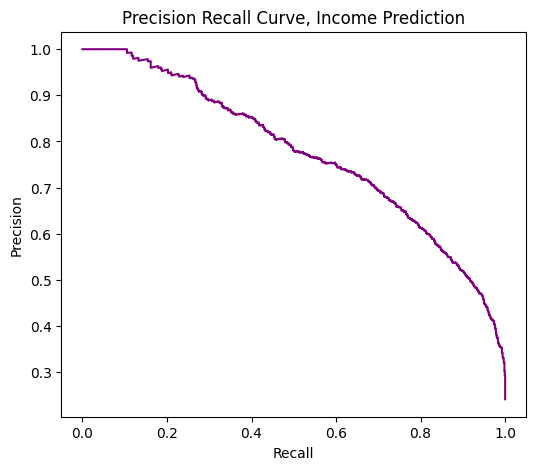

In [ ]:
precision_vals, recall_vals, thresholds = precision_recall_curve(y_test, y_pred_prob)
plt.figure(figsize=(6, 5))
plt.plot(recall_vals, precision_vals, color='purple')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision Recall Curve, Income Prediction')
plt.show()


#Threshold Tuning

In [ ]:
# Finding the threshold that gives the best F1 score
best_f1 = 0
best_threshold = 0.5
for t in np.arange(0.1, 0.9, 0.01):                          # scanning thresholds from 0.1 to 0.9
    preds_t = (y_pred_prob >= t).astype(int)
    f1 = f1_score(y_test, preds_t)
    if f1 > best_f1:
        best_f1 = f1
        best_threshold = t

print(f"Best threshold: {best_threshold:.2f}, F1 score: {best_f1:.4f}")

# Comparing default threshold vs tuned threshold
y_pred_tuned = (y_pred_prob >= best_threshold).astype(int)
print("\nClassification report with tuned threshold:")
print(classification_report(y_test, y_pred_tuned, target_names=['<=50K', '>50K']))


Best threshold: 0.62, F1 score: 0.7006

Classification report with tuned threshold:
              precision    recall  f1-score   support

       <=50K       0.91      0.88      0.90      3709
        >50K       0.67      0.74      0.70      1176

    accuracy                           0.85      4885
   macro avg       0.79      0.81      0.80      4885
weighted avg       0.85      0.85      0.85      4885



#Featur Importance

/tmp/ipykernel_1534/750442214.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df, y='feature', x='importance', palette='viridis')


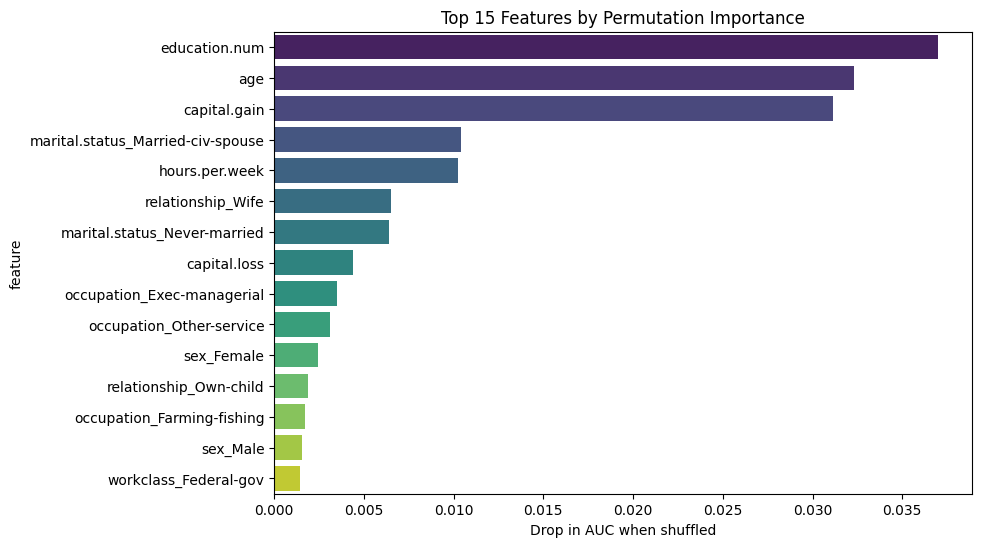

In [ ]:
def permutation_importance_nn(model, X, y_true, baseline_auc, feature_names, n_repeats=3):
    importances = []
    X_array = X.toarray() if hasattr(X, 'toarray') else np.array(X)   # handling sparse matrix output from OneHotEncoder

    for i in range(X_array.shape[1]):
        scores = []
        for _ in range(n_repeats):
            X_permuted = X_array.copy()
            np.random.shuffle(X_permuted[:, i])                        # shuffling one feature column at a time
            preds = model.predict(X_permuted, verbose=0).flatten()
            score = roc_auc_score(y_true, preds)
            scores.append(baseline_auc - score)                         # drop in AUC after shuffling
        importances.append(np.mean(scores))
    return importances

# Getting feature names after one hot encoding
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(ohe_feature_names)          # combining numeric and encoded categorical names

# Running permutation importance, limited to a subset for speed in classroom demo
importances = permutation_importance_nn(model, X_test_processed, y_test, auc_score, all_feature_names, n_repeats=2)

importance_df = pd.DataFrame({
    'feature': all_feature_names,
    'importance': importances
}).sort_values('importance', ascending=False).head(15)                  # top 15 most important features

plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, y='feature', x='importance', palette='viridis')
plt.title('Top 15 Features by Permutation Importance')
plt.xlabel('Drop in AUC when shuffled')
plt.show()


#Save Model

In [ ]:
import joblib

# Seedha Google Drive ke folder mein permanent save karein
model.save('/content/drive/MyDrive/Data of Dl/adult/adult_model.keras')
joblib.dump(preprocessor, '/content/drive/MyDrive/Data of Dl/adult/adult_preprocessor.pkl')

print("Model and preprocessor saved directly to Google Drive!")

Model and preprocessor saved directly to Google Drive!


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   education.num   32561 non-null  int64 
 3   marital.status  32561 non-null  object
 4   occupation      32561 non-null  object
 5   relationship    32561 non-null  object
 6   race            32561 non-null  object
 7   sex             32561 non-null  object
 8   capital.gain    32561 non-null  int64 
 9   capital.loss    32561 non-null  int64 
 10  hours.per.week  32561 non-null  int64 
 11  native.country  32561 non-null  object
 12  income          32561 non-null  int64 
dtypes: int64(6), object(7)
memory usage: 3.2+ MB


#Production style Interface

In [ ]:
def predict_income(raw_person_df, model, preprocessor, threshold=best_threshold):
    processed = preprocessor.transform(raw_person_df)
    probabilities = model.predict(processed, verbose=0).flatten()
    labels = (probabilities >= threshold).astype(int)

    results = raw_person_df.copy()
    results['high_income_probability'] = probabilities.round(4)
    results['predicted_income'] = np.where(labels == 1, '>50K', '<=50K')
    return results

sample_people = X_test.iloc[:5]
prediction_output = predict_income(sample_people, model, preprocessor)
prediction_output[['age', 'education.num', 'occupation', 'capital.gain', 'high_income_probability', 'predicted_income']]

,age,education.num,occupation,capital.gain,high_income_probability,predicted_income
16402,20,9,Tech-support,0,0.0379,<=50K
21837,17,7,Sales,0,0.0007,<=50K
9208,30,7,Machine-op-inspct,0,0.1159,<=50K
8996,28,10,Adm-clerical,0,0.0100,<=50K
8782,42,10,Tech-support,0,0.1788,<=50K
